# S02 · 阈值法：为什么必须「按日历日」

> **Day 2 / 14** ｜ 对应论文章节 **3.3（Threshold definition）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 解释固定阈值、年分位数、日历日滑动窗分位数三者的差别
- 说清楚 ±7 天窗口、`type = 8`、基准期各自在控制什么
- 演示「固定阈值会造成季节性偏差」这件事有多严重
- 做一张阈值敏感性表，作为论文的补充材料

---

## 1. 加载

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
d <- load_clean_daily()

STATION <- "Kuantan"     # 东海岸站，季节性强，适合演示
s <- d %>% filter(station == STATION) %>% arrange(date)
s <- s[format(s$date, "%m-%d") != "02-29", ]

doy <- as.integer(format(s$date, "%j"))
yr  <- as.integer(format(s$date, "%Y"))

cat("站点:", STATION, "  行数:", nrow(s),
    "  时段:", format(min(s$date)), "~", format(max(s$date)), "\n")

站点: Kuantan   行数: 16060   时段: 1980-01-01 ~ 2023-12-31 


---

## 2. 三种阈值的区别

| 做法 | 公式 | 问题 |
|---|---|---|
| **固定物理阈值** | `Tmax > 35 °C` | 与当地气候无关；热带站点常年超标，温带站点永不超标 |
| **全年分位数** | `Tmax > Q90(全年)` | 混入了冬季低温 → 夏季事件虚增、冬季事件为零 |
| **日历日滑动窗分位数** | `Tmax > Q90(该日历日 ±7 天)` | ✅ ETCCDI 标准做法 |

第三种是唯一正确的。下面用数据证明前两种错在哪。

In [3]:
# (a) 全年分位数
th_flat <- quantile(s$tmax[yr %in% CFG$base_years], CFG$prob_default,
                    type = 8, na.rm = TRUE)

# (b) 日历日滑动窗
th_cal <- daily_threshold(doy, s$tmax, yr)

cat(sprintf("全年分位数阈值   : %.2f degC\n", th_flat))
cat(sprintf("日历日阈值       : %.2f ~ %.2f degC (随季节变化)\n",
            min(th_cal), max(th_cal)))

全年分位数阈值   : 34.90 degC


日历日阈值       : 33.00 ~ 35.98 degC (随季节变化)


> 📌 在马来西亚，日历日阈值的季节振幅只有约 1–2 °C —— 远小于温带。**这恰恰意味着它更容易被忽略**：看起来「差不多」，但累积到 44 年就是几千个事件日。

---

## 3. 阈值曲线长什么样

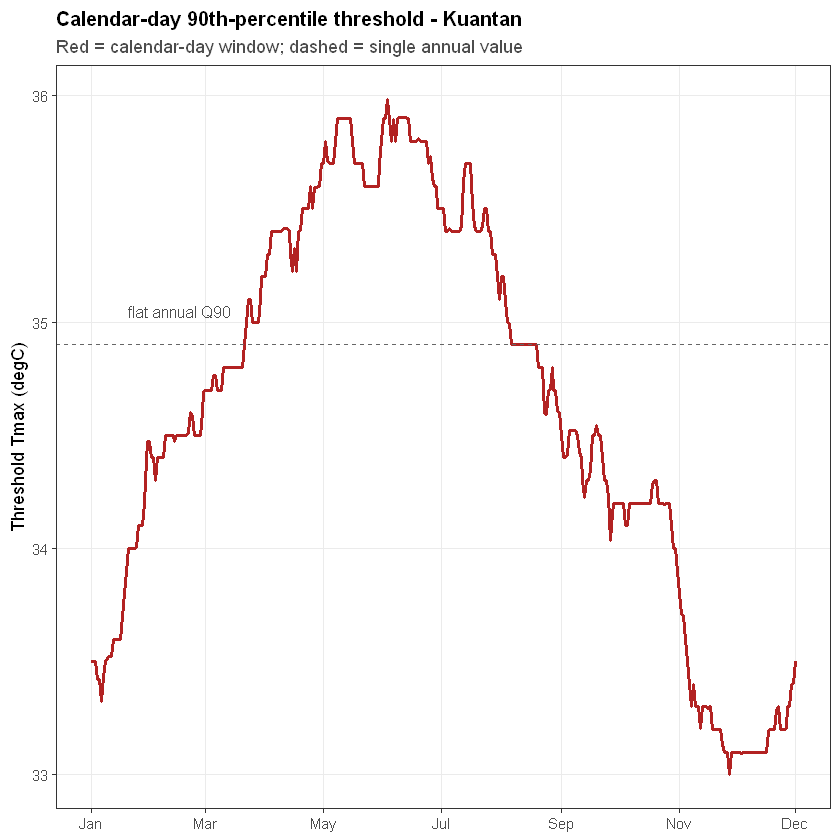

In [4]:
p_th <- data.frame(doy = 1:365, threshold = th_cal,
                   obs_q90 = NA_real_) %>%
  ggplot(aes(doy, threshold)) +
  geom_line(colour = "firebrick", linewidth = 0.9) +
  geom_hline(yintercept = th_flat, linetype = "dashed", colour = "grey40") +
  annotate("text", x = 20, y = th_flat + 0.15,
           label = "flat annual Q90", hjust = 0, size = 3.3, colour = "grey30") +
  scale_x_continuous(breaks = c(1, 60, 121, 182, 244, 305, 365),
                     labels = c("Jan", "Mar", "May", "Jul", "Sep", "Nov", "Dec")) +
  labs(x = NULL, y = "Threshold Tmax (degC)",
       title = paste("Calendar-day 90th-percentile threshold -", STATION),
       subtitle = "Red = calendar-day window; dashed = single annual value") +
  theme_paper()

save_fig(p_th, "S02_threshold_curve", 6.5, 4)
p_th

---

## 4. 固定阈值错在哪：按月看超阈值率

如果阈值是「全年一个数」，那么**夏季超阈值率会远高于 10%，冬季接近 0**。这就是伪信号。

In [5]:
s$ex_flat <- s$tmax > th_flat
s$ex_cal  <- s$tmax > th_cal[doy]
s$month   <- factor(lubridate::month(s$date), levels = 1:12,
                    labels = month.abb)

cmp <- s %>%
  group_by(month) %>%
  summarise(flat = mean(ex_flat, na.rm = TRUE),
            calendar = mean(ex_cal, na.rm = TRUE), .groups = "drop")

print(cmp, n = 12)

# A tibble: 12 × 3
   month   flat calendar
   <fct>  <dbl>    <dbl>
 1 Jan   0.0222   0.104 
 2 Feb   0.0500   0.0893
 3 Mar   0.0936   0.0973
 4 Apr   0.151    0.0957
 5 May   0.228    0.0935
 6 Jun   0.190    0.0826
 7 Jul   0.172    0.102 
 8 Aug   0.0858   0.0917
 9 Sep   0.0560   0.104 
10 Oct   0.0356   0.0822
11 Nov   0.0107   0.102 
12 Dec   0.0110   0.103 


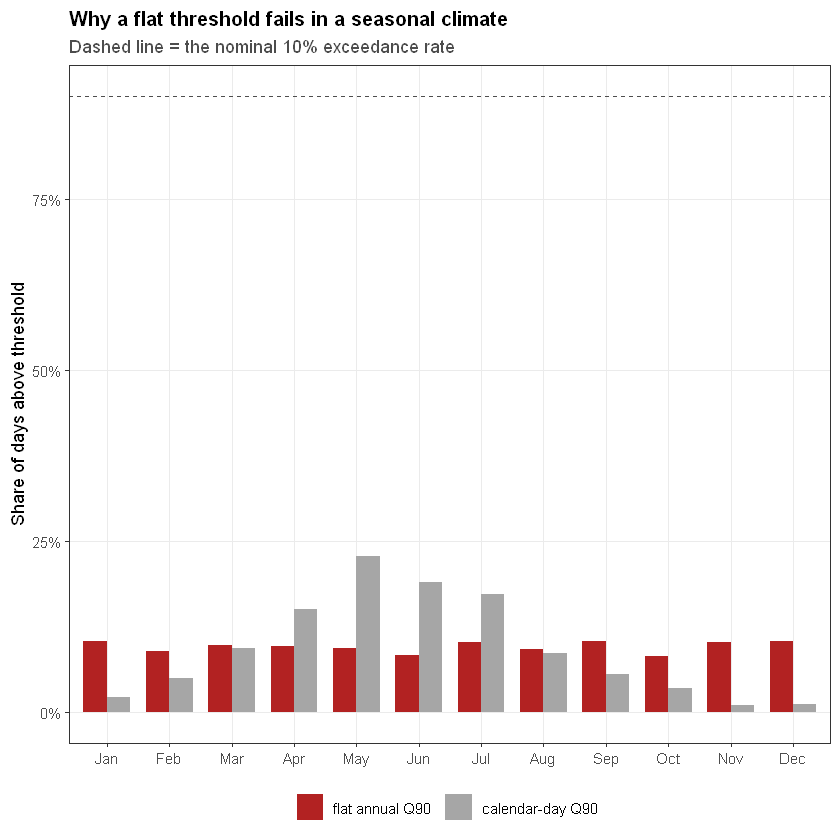

In [6]:
cmp_long <- tidyr::pivot_longer(cmp, c(flat, calendar),
                                names_to = "method", values_to = "rate")

p_month <- ggplot(cmp_long, aes(month, rate, fill = method)) +
  geom_col(position = "dodge", width = 0.75) +
  geom_hline(yintercept = CFG$prob_default, linetype = "dashed", colour = "grey30") +
  scale_fill_manual(values = c(flat = "grey65", calendar = "firebrick"),
                    labels = c("flat annual Q90", "calendar-day Q90")) +
  scale_y_continuous(labels = scales::percent) +
  labs(x = NULL, y = "Share of days above threshold", fill = NULL,
       title = "Why a flat threshold fails in a seasonal climate",
       subtitle = "Dashed line = the nominal 10% exceedance rate") +
  theme_paper()

save_fig(p_month, "S02_seasonal_bias", 6.5, 4)
p_month

> 🔍 **这张图是本节的核心。** 灰柱（固定阈值）在 2–5 月接近 30%，在 11–12 月接近 0%；红柱（日历日阈值）全年稳定在 10% 附近。
>
> 如果你用灰柱的方法，你的「热浪」实际上测量的是**季节**，不是**极端事件**。

---

## 5. 三个参数的取舍

### 5.1 窗口半宽 `halfwin`

| 取值 | 效果 |
|---:|---|
| 3（7 天窗） | 样本少 → 分位数噪声大；适合记录密集的地区 |
| **7（15 天窗）** | ETCCDI 推荐；样本量与代表性平衡 |
| 15（31 天窗） | 更平滑，但会「借」到相邻季节的阈值，削弱季节适应 |

### 5.2 分位数类型 `type`

R 的 `quantile()` 有 9 种算法。ETCCDI / WMO 推荐 **type = 8**（Hyndman–Fan），它是近似无偏的、且对分布尾部更稳健。

In [7]:
x <- s$tmax[!is.na(s$tmax)]
sapply(1:9, function(tp) round(quantile(x, 0.9, type = tp), 3)) %>%
  setNames(paste0("type", 1:9)) %>% print()

type1 type2 type3 type4 type5 type6 type7 type8 type9 
 34.9  34.9  34.9  34.9  34.9  34.9  34.9  34.9  34.9 


> 📌 差别通常只有 0.01–0.05 °C，但**论文里必须写明用了哪一种**，否则无法复现。

### 5.3 基准期

`1985–2014` 是 ETCCDI 的默认，也是 IPCC AR5/AR6 常用的对照期。

In [8]:
cat("当前基准期:", min(CFG$base_years), "-", max(CFG$base_years), "\n")

当前基准期: 1985 - 2014 


> ⚠️ 基准期选择会改变阈值的绝对位置，进而改变事件数。这是 S14 敏感性分析的一项。

---

## 6. 边界效应：12 月 31 日和 1 月 1 日是邻居

如果不做环形处理，12 月 31 日的窗口只取到 12 月 24–31 日 + 1 月 1–7 日**中的一部分**，会产生明显跳变。

In [9]:
th_naive <- rep(NA_real_, 365)
for (dd in 1:365) {
  sel <- (yr %in% CFG$base_years) &
         abs(doy - dd) <= CFG$halfwin & !is.na(s$tmax)     # 注意：这里没有环形距离
  if (sum(sel) >= CFG$min_obs) th_naive[dd] <- quantile(s$tmax[sel], 0.9, type = 8)
}

edge <- data.frame(
  doy = c(1:3, 363:365),
  circular = round(th_cal[c(1:3, 363:365)], 3),
  naive    = round(th_naive[c(1:3, 363:365)], 3)
)
print(edge)
cat("\n年末到年初的跳变：\n")
cat(sprintf("  环形处理: %.3f degC\n", th_cal[1] - th_cal[365]))
cat(sprintf("  朴素处理: %.3f degC  <- 人为断层\n", th_naive[1] - th_naive[365]))

  doy circular  naive
1   1   33.500 33.583
2   2   33.500 33.600
3   3   33.500 33.600
4 363   33.400 33.200
5 364   33.403 33.203
6 365   33.500 33.203



年末到年初的跳变：


  环形处理: 0.000 degC


  朴素处理: 0.380 degC  <- 人为断层


---

## 7. 敏感性网格

论文的补充材料应该有这张表：

In [10]:
grid <- expand.grid(halfwin = c(3, 7, 15),
                    prob    = c(0.90, 0.95),
                    KEEP.OUT.ATTRS = FALSE)

sens <- do.call(rbind, lapply(seq_len(nrow(grid)), function(i) {
  th <- daily_threshold(doy, s$tmax, yr,
                        prob = grid$prob[i], halfwin = grid$halfwin[i])
  data.frame(
    halfwin   = grid$halfwin[i],
    prob      = grid$prob[i],
    mean_th   = round(mean(th), 2),
    th_range  = round(diff(range(th)), 2),
    n_exceed  = sum(s$tmax > th[doy], na.rm = TRUE),
    rate      = round(mean(s$tmax > th[doy], na.rm = TRUE), 4)
  )
}))

print(sens, row.names = FALSE)

 halfwin prob mean_th th_range n_exceed   rate
       3 0.90   34.62     3.36     1566 0.0986
       7 0.90   34.62     2.98     1519 0.0956
      15 0.90   34.62     2.74     1519 0.0956
       3 0.95   35.17     3.58      739 0.0465
       7 0.95   35.18     3.19      750 0.0472
      15 0.95   35.18     2.80      740 0.0466


> 📌 期望：`rate` 应该接近 `1 − prob`（90 百分位 → 约 10% 的日子超标）。如果某一行明显偏离，说明窗口太窄导致分位数不稳。

---

## 8. 本讲产出

In [11]:
cat("产出：\n")
cat(" ", file.path(PATHS$mfig, "S02_threshold_curve.png"), "\n")
cat(" ", file.path(PATHS$mfig, "S02_seasonal_bias.png"), "\n")

产出：


  C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/figs/S02_threshold_curve.png 


  C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/figs/S02_seasonal_bias.png 


---

## 9. 常见错误

| 错误 | 后果 |
|---|---|
| 用全年分位数 | 事件数被季节主导 |
| 用 `quantile()` 默认类型且不声明 | 不可复现 |
| 不做环形距离 | 年末年初出现人为断层 |
| 窗口内样本 <30 仍计算 | 分位数噪声极大 |
| 阈值用全时段（1980–2023）而非基准期 | 与气候变化混淆 |

---

## 10. 自检问题

<details>
<summary>Q1：为什么 fixed threshold（如 35 °C）对马来西亚完全不能用？</summary>

因为 35 °C 在这 10 个站的分布中已经是极端尾部（很多站 44 年最高才 37–38 °C），会出现「有的站一年 0 次、有的站一年 20 次」的荒谬结果。阈值必须相对于当地气候定义。
</details>

<details>
<summary>Q2：为什么 ±7 天窗口的样本量是 30 年 × 15 天 ≈ 450 个？这对 90 百分位够吗？</summary>

够。450 个样本估计 90 百分位的标准误约为 `sqrt(p(1-p)/n)/f(q)`，在热带窄分布下约 0.03 °C。若窗口缩到 ±3 天（210 个样本），标准误翻倍。
</details>

<details>
<summary>Q3：如果某站缺测 30%，窗口内有效样本骤减，会发生什么？</summary>

分位数估计的方差按 1/√n 增大，阈值会年际抖动。极端情况下窗口内样本不足 `min_obs`，阈值被插值填充，等于用邻近日期「猜」——必须在方法章说明。
</details>

<details>
<summary>Q4：为什么论文里必须报告阈值敏感性表？</summary>

因为 90 百分位、±7 天、type 8 全是任意选择。审稿人会问「换一组参数结论还成立吗」。这张表就是答案。如果结论随参数翻转，说明结论不稳健——这本身也是重要发现。
</details>

---

## 下一步

**S03 · 事件提取**：把「超阈值的日子」变成「事件」。游程理论、declustering、以及为什么最短持续 3 天。